In [66]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from keras.models import load_model

# 1. CARGAR DATOS
ruta_limpia = r'Data\Raw_data\100.npz'
datos = np.load(ruta_limpia)
X_data = datos['X']
Y_data = datos['Y']

# 2. MAPEO FIJO DE CLASES (Debe ser estricto para que coincida con el entrenamiento)
clases_viables = ['N', '/', 'R', 'L', 'V', 'A', 'f', 'F']
etiquetas_finales = clases_viables + ['No_Clasificable']

mapeo_clases = {clase: i for i, clase in enumerate(clases_viables)}

# Todo lo que no esté en las 8 clases principales, se convierte en la clase 8 (No_Clasificable)
Y_numerico = np.array([mapeo_clases.get(etiqueta, 8) for etiqueta in Y_data])

print(f"Latidos totales en este registro de paciente: {len(Y_numerico)}")

Latidos totales en este registro de paciente: 2272


In [67]:
# 3. PREPARAR TENSORES Y ONE-HOT
X_cnn = np.expand_dims(X_data, axis=-1)

# Aseguramos que siempre haya 9 columnas, sin importar cuántas clases tenga el paciente
Y_onehot = tf.keras.utils.to_categorical(Y_numerico, num_classes=9)

# Opcional: Si solo quieres evaluar el rendimiento general del paciente, podrías 
# predecir sobre TODO el archivo sin hacer split. Pero mantendremos el split si así lo requieres.
X_train, X_val, y_train, y_val = train_test_split(X_cnn, Y_onehot, test_size=0.2, random_state=42)

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step


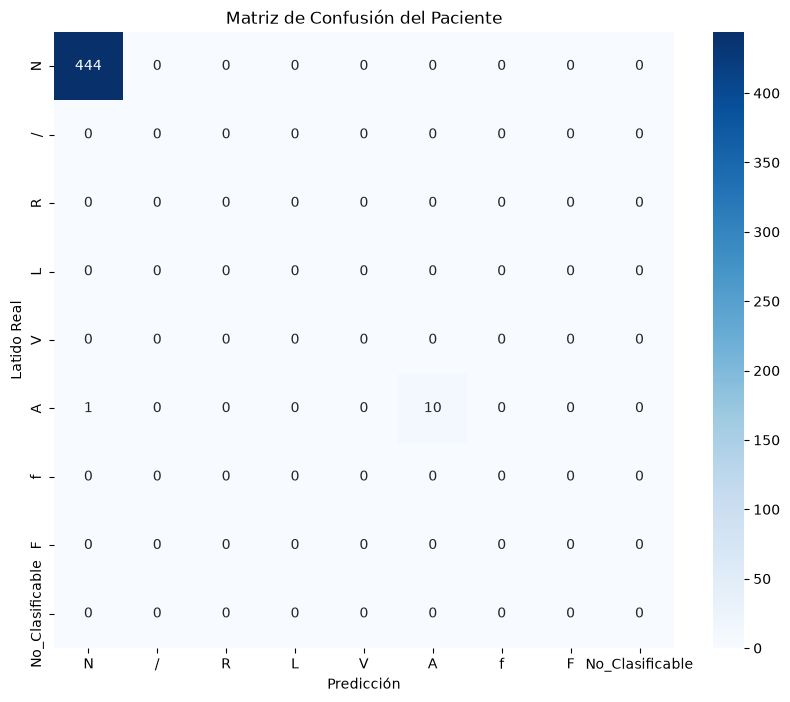


=== REPORTE DE CLASIFICACIÓN ===
                 precision    recall  f1-score   support

              N       1.00      1.00      1.00       444
              /       0.00      0.00      0.00         0
              R       0.00      0.00      0.00         0
              L       0.00      0.00      0.00         0
              V       0.00      0.00      0.00         0
              A       1.00      0.91      0.95        11
              f       0.00      0.00      0.00         0
              F       0.00      0.00      0.00         0
No_Clasificable       0.00      0.00      0.00         0

       accuracy                           1.00       455
      macro avg       0.22      0.21      0.22       455
   weighted avg       1.00      1.00      1.00       455

La clase '/' no está presente en la muestra de este paciente. Omitiendo ROC.
La clase 'R' no está presente en la muestra de este paciente. Omitiendo ROC.
La clase 'L' no está presente en la muestra de este paciente. Omitie

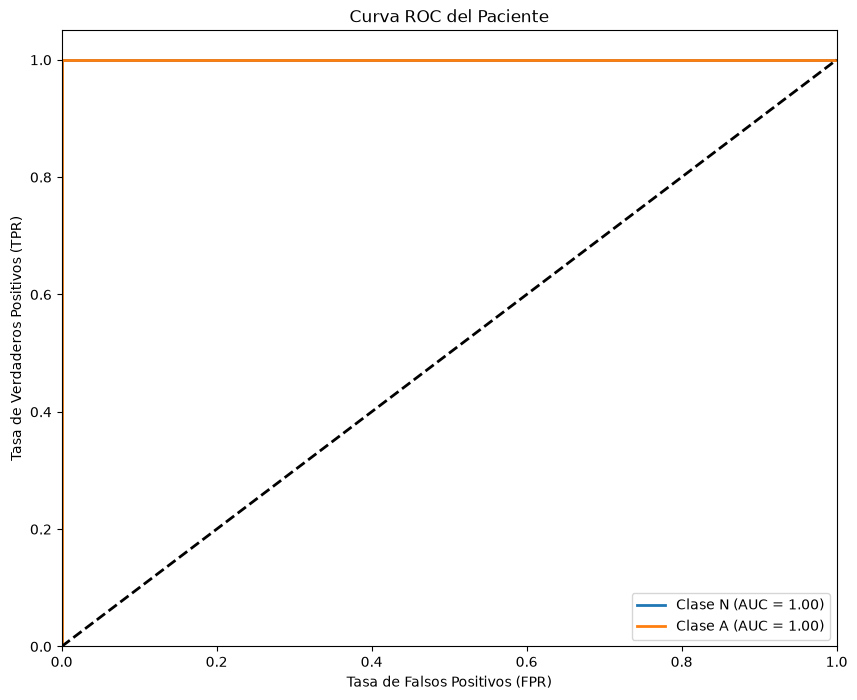

In [68]:
# ========================================================
# 4. DECLARAR LA FUNCIÓN DE PÉRDIDA ANTES DE CARGAR
# ========================================================
# Importación segura del decorador según tu versión de Keras/TensorFlow
try:
    from keras.saving import register_keras_serializable
except ImportError:
    from tensorflow.keras.utils import register_keras_serializable

PENALIDAD_RECHAZO = 2.0 

@register_keras_serializable()
def custom_rejection_loss(y_true, y_pred):
    y_true_reject = y_true[:, -1]
    y_pred_reject = y_pred[:, -1]
    ce_loss = -tf.reduce_sum(y_true * tf.math.log(y_pred + 1e-9), axis=-1)
    penalizacion = (1.0 - y_true_reject) * (y_pred_reject * PENALIDAD_RECHAZO)
    return tf.reduce_mean(ce_loss + penalizacion)

# Cargamos el modelo pasando los objetos personalizados
modelo = load_model(r'Data\Models\modelo_arritmias_cnn_6.0.keras', 
                    custom_objects={'custom_rejection_loss': custom_rejection_loss})

# Predicciones
y_pred_prob = modelo.predict(X_val)
y_pred_clases = np.argmax(y_pred_prob, axis=1)
y_val_int = np.argmax(y_val, axis=1)

# ========================================================
# 5. MATRIZ DE CONFUSIÓN Y REPORTE
# ========================================================
# Forzamos labels=np.arange(9) para que la matriz sea siempre de 9x9 aunque falten clases
matriz = confusion_matrix(y_val_int, y_pred_clases, labels=np.arange(9))

plt.figure(figsize=(10, 8))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', 
            xticklabels=etiquetas_finales, yticklabels=etiquetas_finales)
plt.title('Matriz de Confusión del Paciente')
plt.ylabel('Latido Real')
plt.xlabel('Predicción')
plt.show()

print("\n=== REPORTE DE CLASIFICACIÓN ===")
print(classification_report(y_val_int, y_pred_clases, target_names=etiquetas_finales, labels=np.arange(9), zero_division=0))

# ========================================================
# 6. CURVA ROC A PRUEBA DE CLASES FALTANTES
# ========================================================
plt.figure(figsize=(10, 8))
for i in range(9):
    # La curva ROC falla si una clase no tiene ni una sola muestra en y_val
    if np.sum(y_val[:, i]) > 0:
        fpr, tpr, _ = roc_curve(y_val[:, i], y_pred_prob[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'Clase {etiquetas_finales[i]} (AUC = {roc_auc:.2f})')
    else:
        print(f"La clase '{etiquetas_finales[i]}' no está presente en la muestra de este paciente. Omitiendo ROC.")

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC del Paciente')
plt.legend(loc="lower right")
plt.show()